# 04. Segmentación de Valor (Clustering + PCA), Calibración y Umbrales (TF1 - CC209)

**Objetivo:**
1. Incorporar **Clustering No Supervisado** (técnica de la segunda mitad del curso) comparando **K-Means**, **GMM** y **Jerárquico (Ward)** + proyección **PCA 2D** sobre `Train + Val` para crear **perfiles/proxies de valor y vinculación** (sin afirmar CLV o RFM transaccional real).
2. Evaluar **calibración probabilística OOF** (`none`, `sigmoid`, `isotonic`) mediante Brier Score y Log-Loss.
3. Optimizar en OOF el **umbral operativo global** ($\tau^* = 0.20$) y los **umbrales dinámicos por segmento de valor**, explicando la paradoja del óptimo Bayesiano irrestricto (`0.05`).
4. Ejecutar la **evaluación única en Test Holdout** (`1,057` filas) incluyendo **Value-Weighted Recall** y análisis de **sensibilidad económica** en 3 escenarios.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.config import REPORTS_DIR, MODELS_DIR, FIGURES_TF1_DIR

with open(MODELS_DIR / "metadata_tf1.json", "r", encoding="utf-8") as f:
    metadata = json.load(f)
print("Modelo ganador:", metadata["winner_name"])
print("Calibración seleccionada:", metadata["calibration_method"])
print("Umbral global operativo tau*:", metadata["global_threshold"])
print("Óptimo Bayesiano irrestricto (referencia):", metadata["unconstrained_bayes_threshold"])

Modelo ganador: Stacking Heterogéneo (LR+LGBM+XGB)
Calibración seleccionada: none
Umbral global operativo tau*: 0.2
Óptimo Bayesiano irrestricto (referencia): 0.05


## 1. Comparación de Algoritmos de Clustering y Proyección PCA 2D

,Algoritmo,k,Soporta_Predict_Online,Silhouette,Davies_Bouldin,Calinski_Harabasz,Inercia,BIC
0,K-Means,2,True,0.4488,0.8737,6817.7996,11192.2489,NaN
1,GMM,2,True,0.3781,1.0635,4705.9344,NaN,26177.9608
2,Jerárquico (Ward),2,False,0.4259,0.9495,5854.7834,NaN,NaN
3,K-Means,3,True,0.4394,0.9158,6588.3830,7476.9969,NaN
4,GMM,3,True,0.4006,0.8706,4916.9931,NaN,1165.8545
5,Jerárquico (Ward),3,False,0.4154,0.7522,5024.4032,NaN,NaN
6,K-Means,4,True,0.4141,0.8603,6626.1677,5538.7248,NaN
7,GMM,4,True,0.2866,1.3444,3937.1729,NaN,-3923.6002
8,Jerárquico (Ward),4,False,0.3393,0.8979,5477.1711,NaN,NaN
9,K-Means,5,True,0.3858,0.8935,6848.9316,4290.6905,NaN


,Cluster_ID,Cluster_Label,Clientes,Tenure_Medio,MonthlyCharges_Medio,TotalCharges_Medio,Servicios_Medios,Pct_Mes_a_Mes,Pct_Fibra,Tasa_Churn_Observada,Pct_Cartera
0,0,Bajo Valor / Entrada,1539,28.8155,23.0590,670.5404,1.1618,0.4165,0.0000,0.1014,0.2571
1,1,Valor Medio / Estándar,1888,9.0651,70.1101,630.9195,3.4237,0.9216,0.5747,0.5011,0.3154
2,2,Alto Valor / Consolidado,2559,51.5975,86.5266,4480.5243,5.5303,0.3603,0.6135,0.1899,0.4275


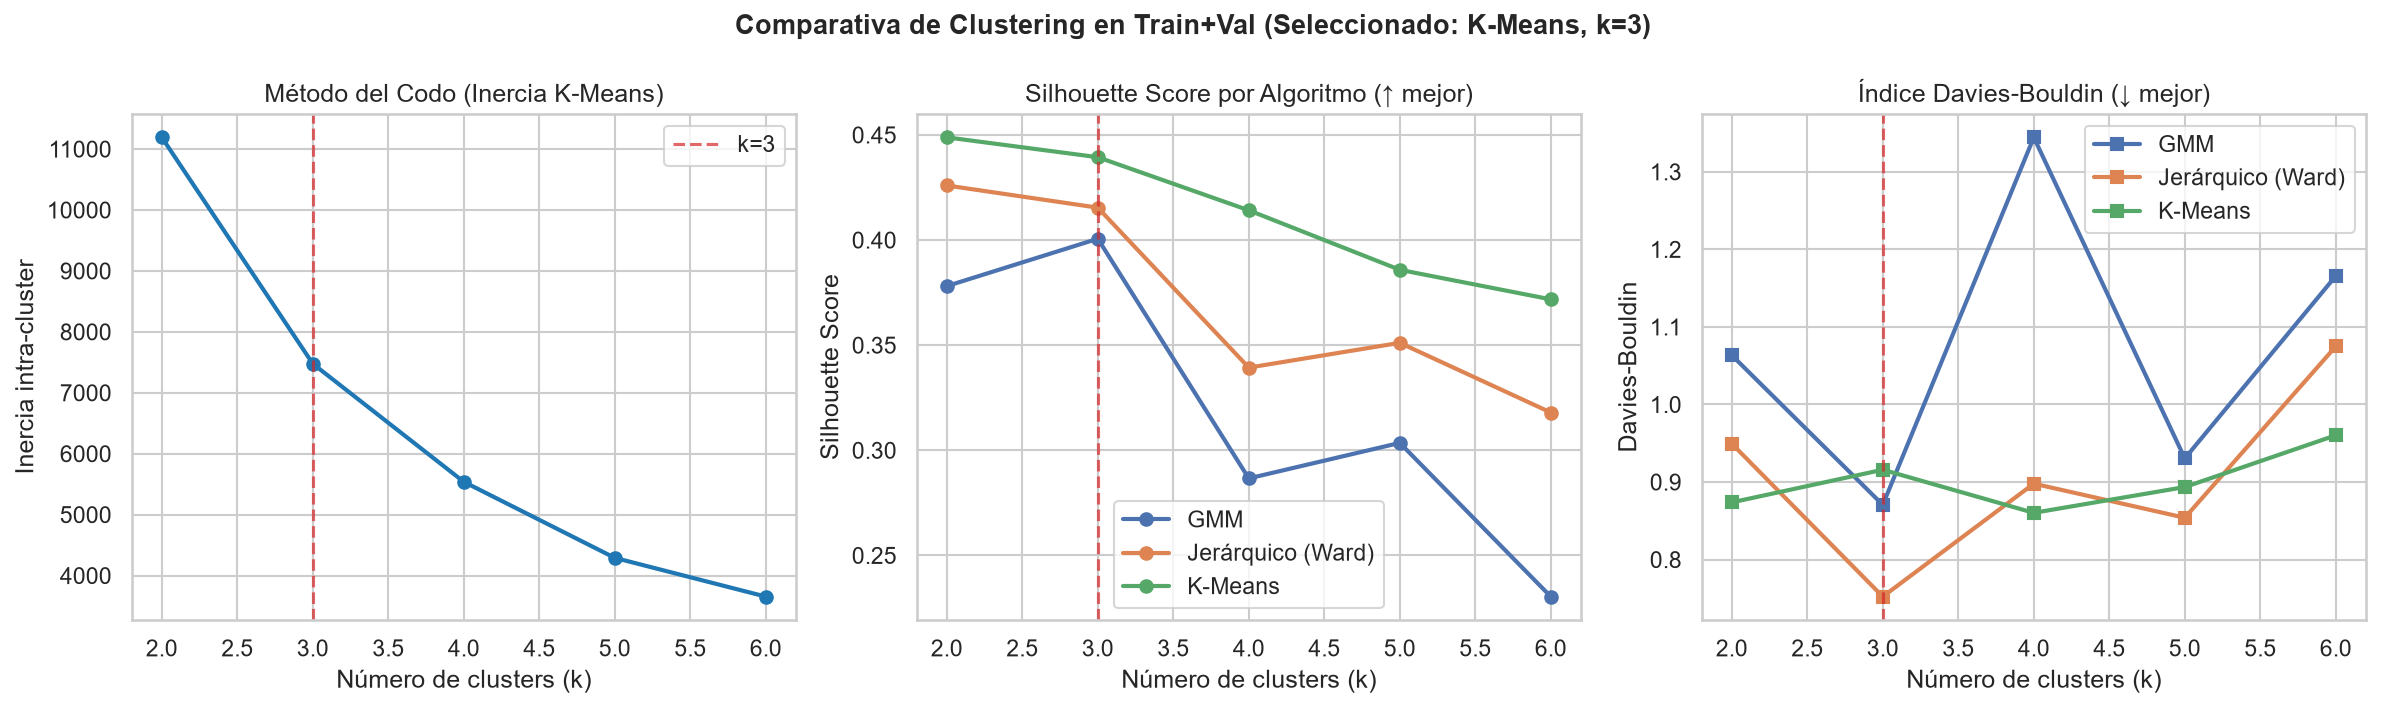

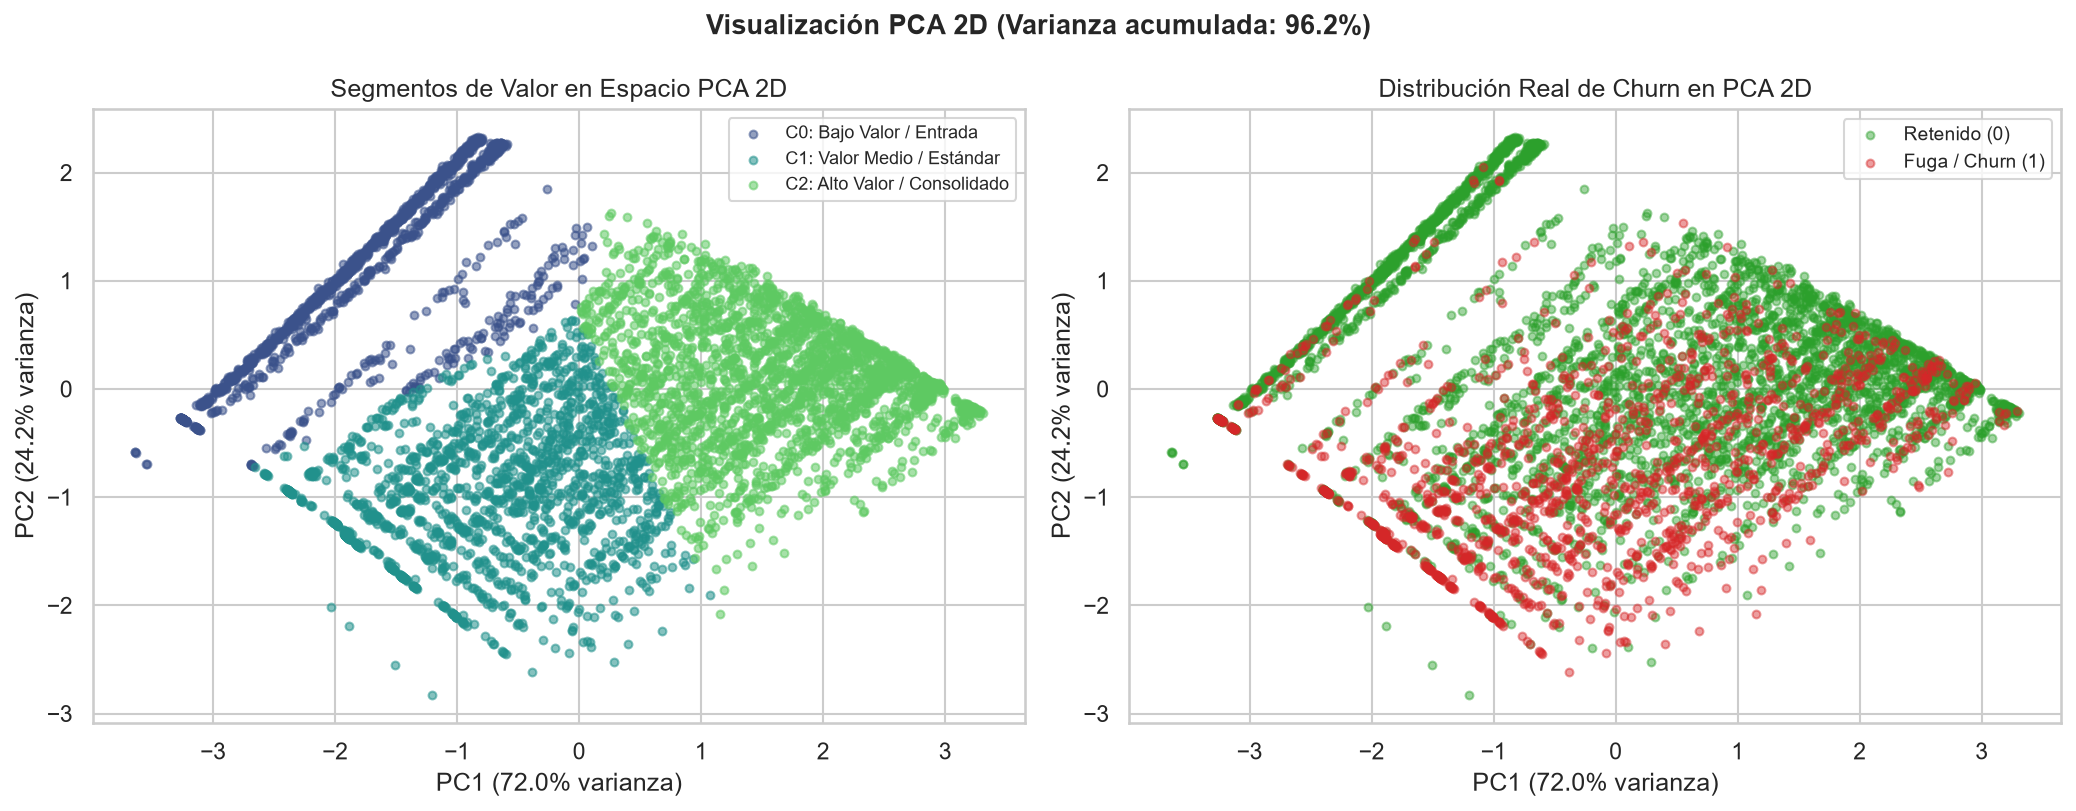

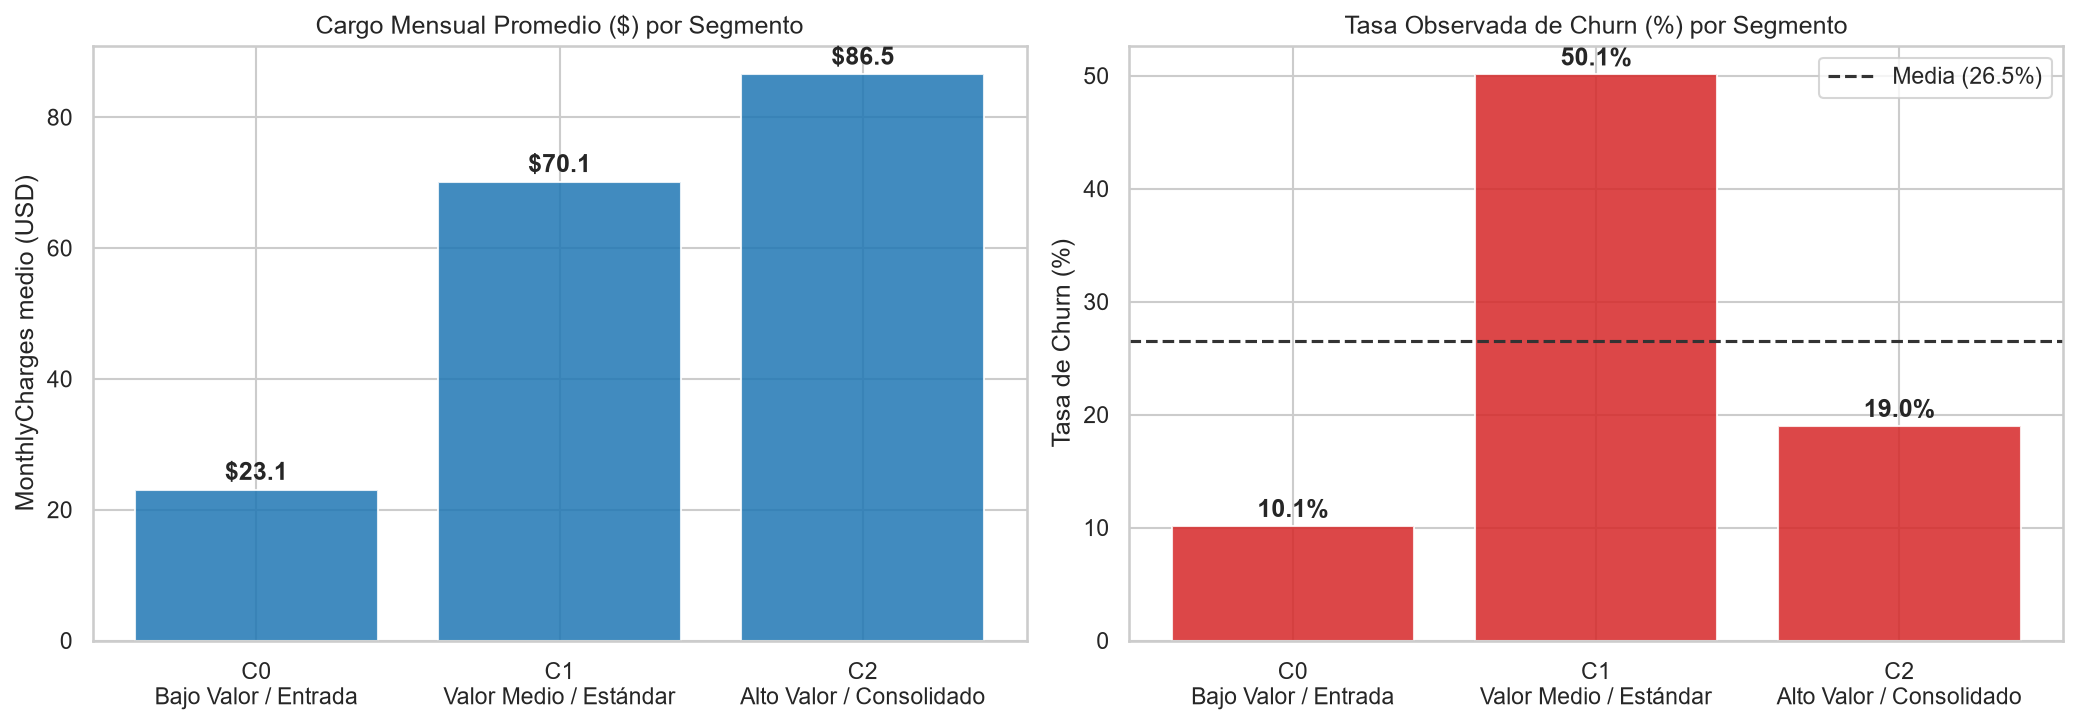

In [2]:
df_clust = pd.read_csv(REPORTS_DIR / "comparacion_clustering_tf1.csv")
display(df_clust.round(4))

df_prof = pd.read_csv(REPORTS_DIR / "perfiles_clusters_tf1.csv")
display(df_prof.round(4))

display(Image(filename=str(FIGURES_TF1_DIR / "clustering_metricas_k.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "clustering_pca_2d.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "clustering_perfiles_valor.png")))

**Interpretación del Clustering y PCA:**
- **Elección técnica:** Dentro del rango accionable $k \in \{3, 4\}$, **K-Means ($k=3$)** alcanza el mayor **Silhouette Score (`0.4394`)**, superando a GMM (`0.4006`) y Jerárquico Ward (`0.4154`), además de permitir asignación instantánea `.predict()` sobre nuevos clientes. La proyección **PCA 2D** retiene **96.17%** de la varianza de las 4 variables de valor (`tenure`, `MonthlyCharges`, `TotalCharges`, `TotalServicesSubscribed`).
- **Hallazgo de negocio:**
  - **C0 — Bajo Valor / Entrada (25.7% cartera):** ticket bajo (`$23.06/mes`), 0% fibra óptica, **Churn = 10.1%**.
  - **C1 — Valor Medio / Estándar (31.5% cartera):** antigüedad muy baja (`9.1` meses), ticket alto (`$70.11/mes`), 92.2% contrato mes a mes, **Churn crítico = 50.1%**.
  - **C2 — Alto Valor / Consolidado (42.7% cartera):** antigüedad alta (`51.6` meses), mayor facturación (`$86.53/mes`, `$4,480.52` acumulados) y empaquetamiento (`5.53` servicios), **Churn = 19.0%**.

## 2. Calibración Probabilística OOF y Optimización de Umbrales

,Metodo_Calibracion,PR-AUC_OOF,ROC-AUC_OOF,Brier_Score_OOF,Log_Loss_OOF
0,none,0.66679,0.85056,0.13332,0.41311
1,sigmoid,0.66560,0.85030,0.13346,0.41332
2,isotonic,0.65048,0.84519,0.13357,0.41993


,Modelo,Recall (Clase 1),Value-Weighted Recall,Precision (Clase 1),F1-Score,Valor Económico Neto ($)
0,OOF Umbral Fijo 0.50,0.5516,0.5836,0.6651,0.6031,-71450.0
1,OOF Umbral Global Operativo (0.20),0.8451,0.8603,0.5019,0.6298,280100.0
2,OOF Umbrales Dinámicos por Cluster,0.8155,0.8460,0.5199,0.6350,246950.0


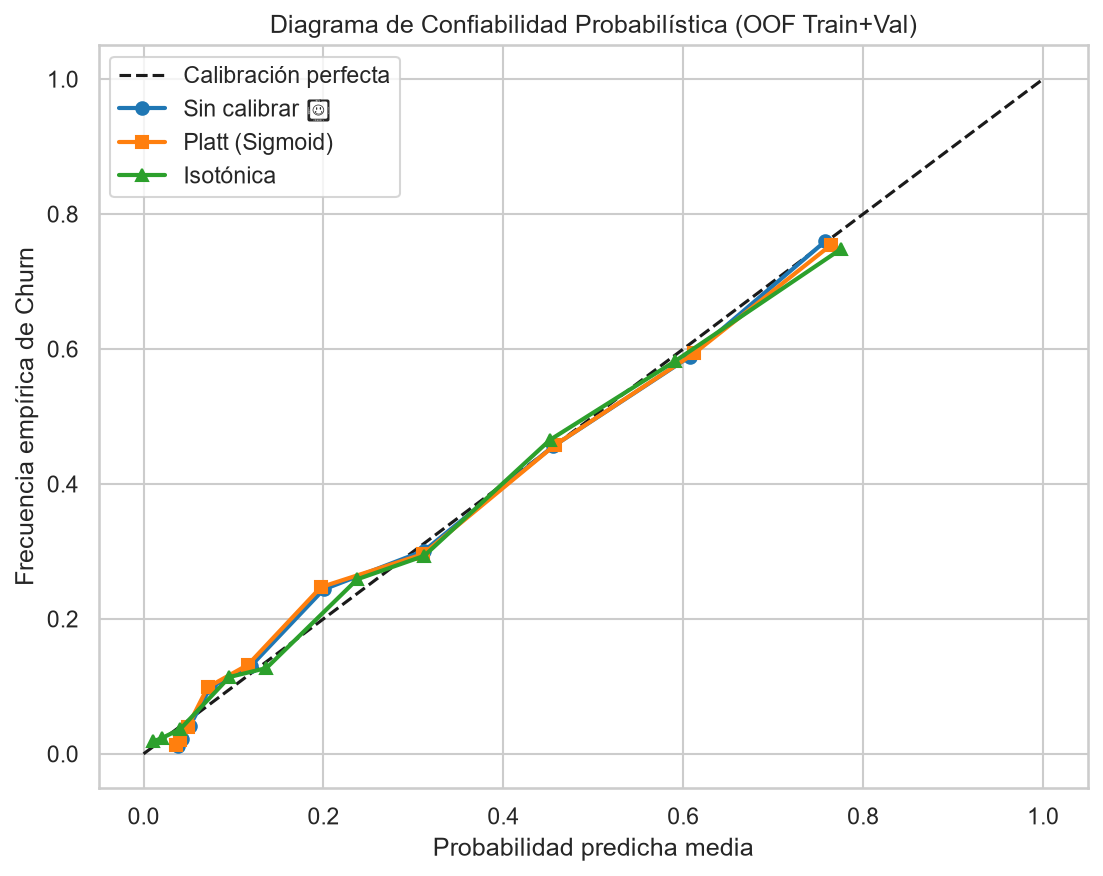

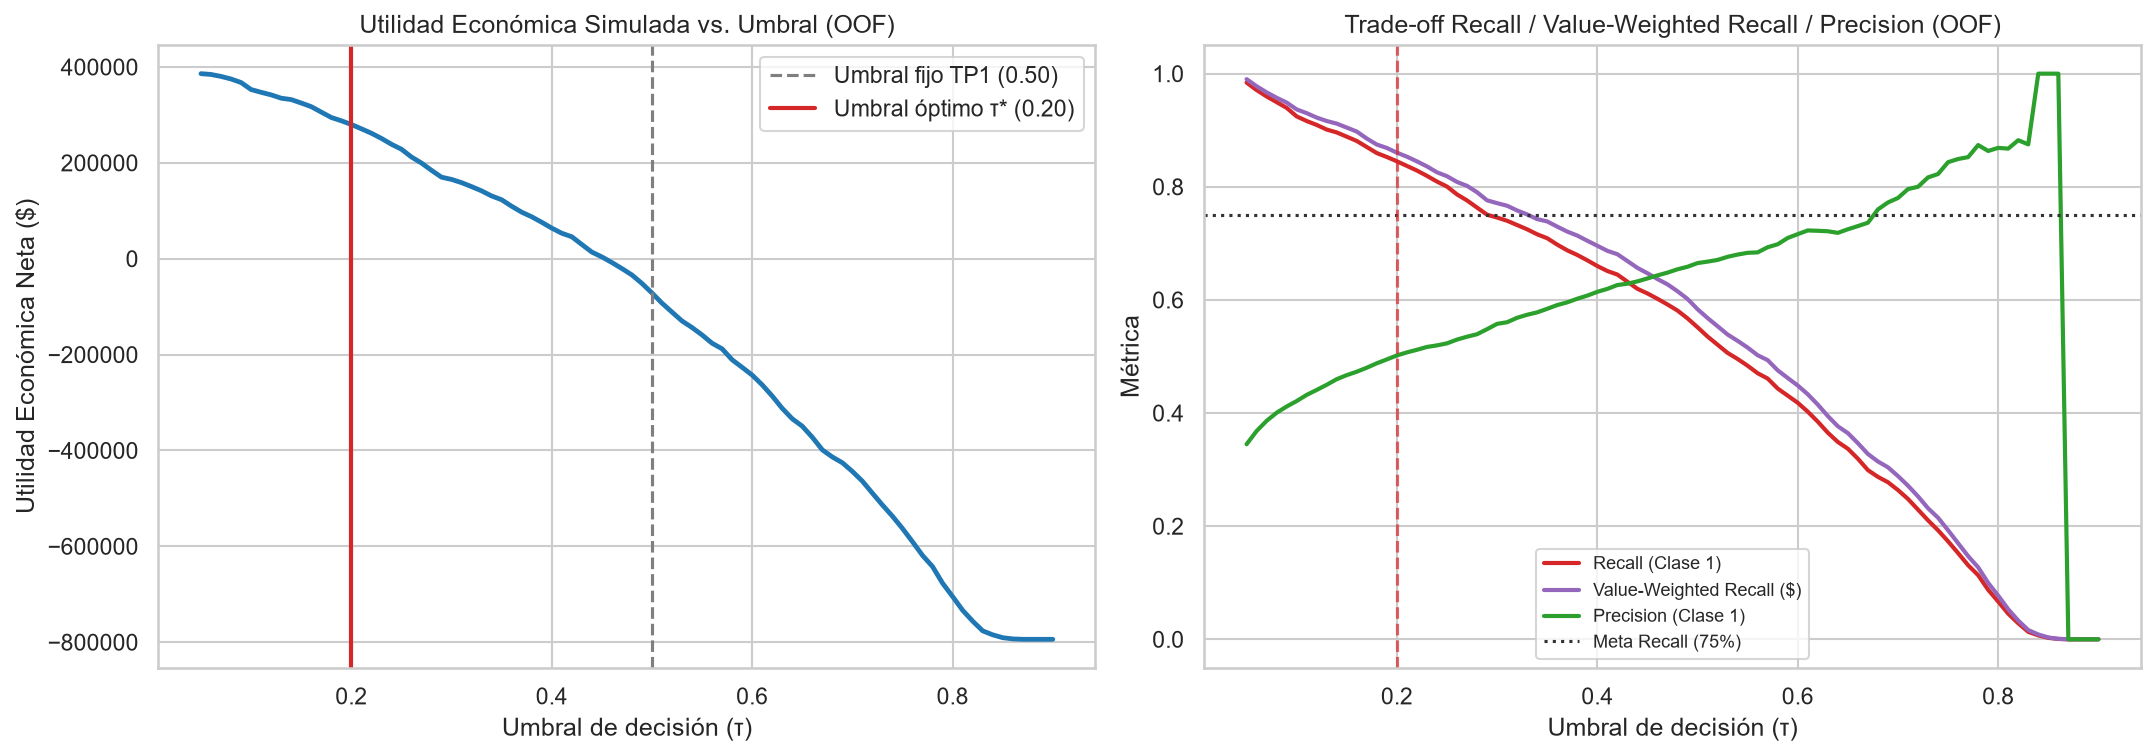

In [3]:
df_cal = pd.read_csv(REPORTS_DIR / "calibracion_oof_tf1.csv")
display(df_cal.round(5))

df_oof_thr = pd.read_csv(REPORTS_DIR / "comparacion_umbrales_oof_tf1.csv")
display(df_oof_thr[["Modelo", "Recall (Clase 1)", "Value-Weighted Recall", "Precision (Clase 1)", "F1-Score", "Valor Económico Neto ($)"]].round(4))

display(Image(filename=str(FIGURES_TF1_DIR / "calibracion_probabilidades.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "curva_umbral_utilidad.png")))

**Interpretación:**
- **Calibración:** `StackingClassifier` utiliza una Regresión Logística meta sobre las probabilidades base, por lo que ya exhibe la mejor calibración OOF sin necesidad de post-calibración adicional (`Brier Score = 0.1333`, mejor que Platt `0.1335` e Isotónica `0.1336`).
- **Paradoja Bayesiana vs. Selectividad Operativa:** Bajo la relación de costos `FN=$500` vs `FP=$50` (`TP=+$350`), el óptimo Bayesiano irrestricto cae a $\tau \approx 0.05$, lo que obligaría a intervenir al ~76% de toda la cartera (`Precision ~ 34.5%`). Para preservar el objetivo de evitar campañas indiscriminadas, imponemos en OOF la restricción operativa `Recall >= 75%` y `Precision >= 50%`, seleccionando **$\tau^* = 0.20$** (`Recall OOF = 84.5%`, `Value-Weighted Recall = 86.0%`, `Precision = 50.2%`).

## 3. Evaluación Final Única en Test Holdout y Sensibilidad Económica

,Modelo,PR-AUC,ROC-AUC,Recall (Clase 1),Value-Weighted Recall,Precision (Clase 1),F1-Score,Valor Económico Neto ($)
0,Baseline Trivial (Dummy),0.2658,0.5000,0.0000,0.0000,0.0000,0.0000,-140500.0
1,Baseline Heurístico (Mes-a-Mes & Tenure <= 6),0.3999,0.6596,0.4377,0.3729,0.5721,0.4960,-40550.0
2,"TP1: Random Forest (depth=10, umbral 0.50)",0.6698,0.8400,0.7046,0.7411,0.5756,0.6336,20500.0
3,TF1: Stacking Heterogéneo (LR+LGBM+XGB) (umbra...,0.6719,0.8443,0.5089,0.5495,0.6714,0.5789,-22450.0
4,TF1: Stacking Heterogéneo (LR+LGBM+XGB) (umbra...,0.6719,0.8443,0.8114,0.8412,0.4935,0.6137,41600.0
5,TF1: Stacking Heterogéneo (LR+LGBM+XGB) (umbra...,0.6719,0.8443,0.7651,0.8198,0.5095,0.6117,31900.0


Escenario,Escenario Agresivo (Costo intervención FP = $100),Escenario Base (Supuesto TP1),Escenario Pesimista (30% efectividad de retención)
Modelo,,,
Baseline Heurístico,-45150.0,-40550.0,-70685.0
Baseline Trivial (Dummy),-140500.0,-140500.0,-140500.0
TF1 Umbral Global (0.20),29900.0,41600.0,-14260.0
TF1 Umbrales Dinámicos,21550.0,31900.0,-20775.0
TP1: Random Forest (0.50),13200.0,20500.0,-28010.0


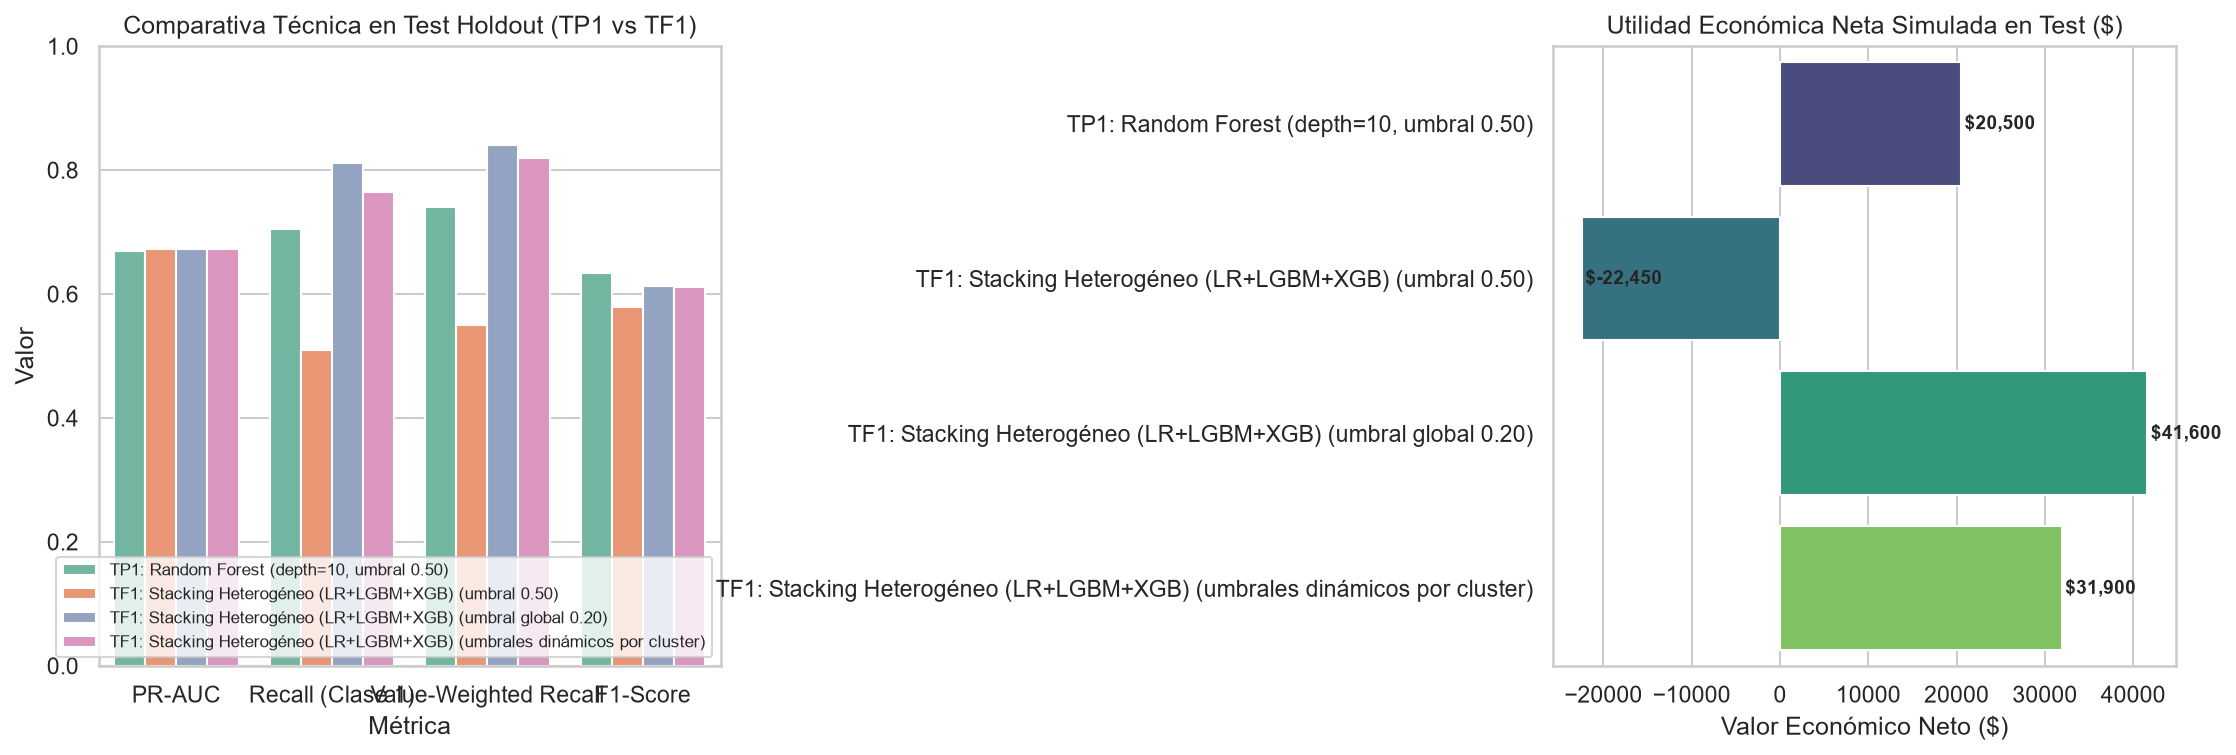

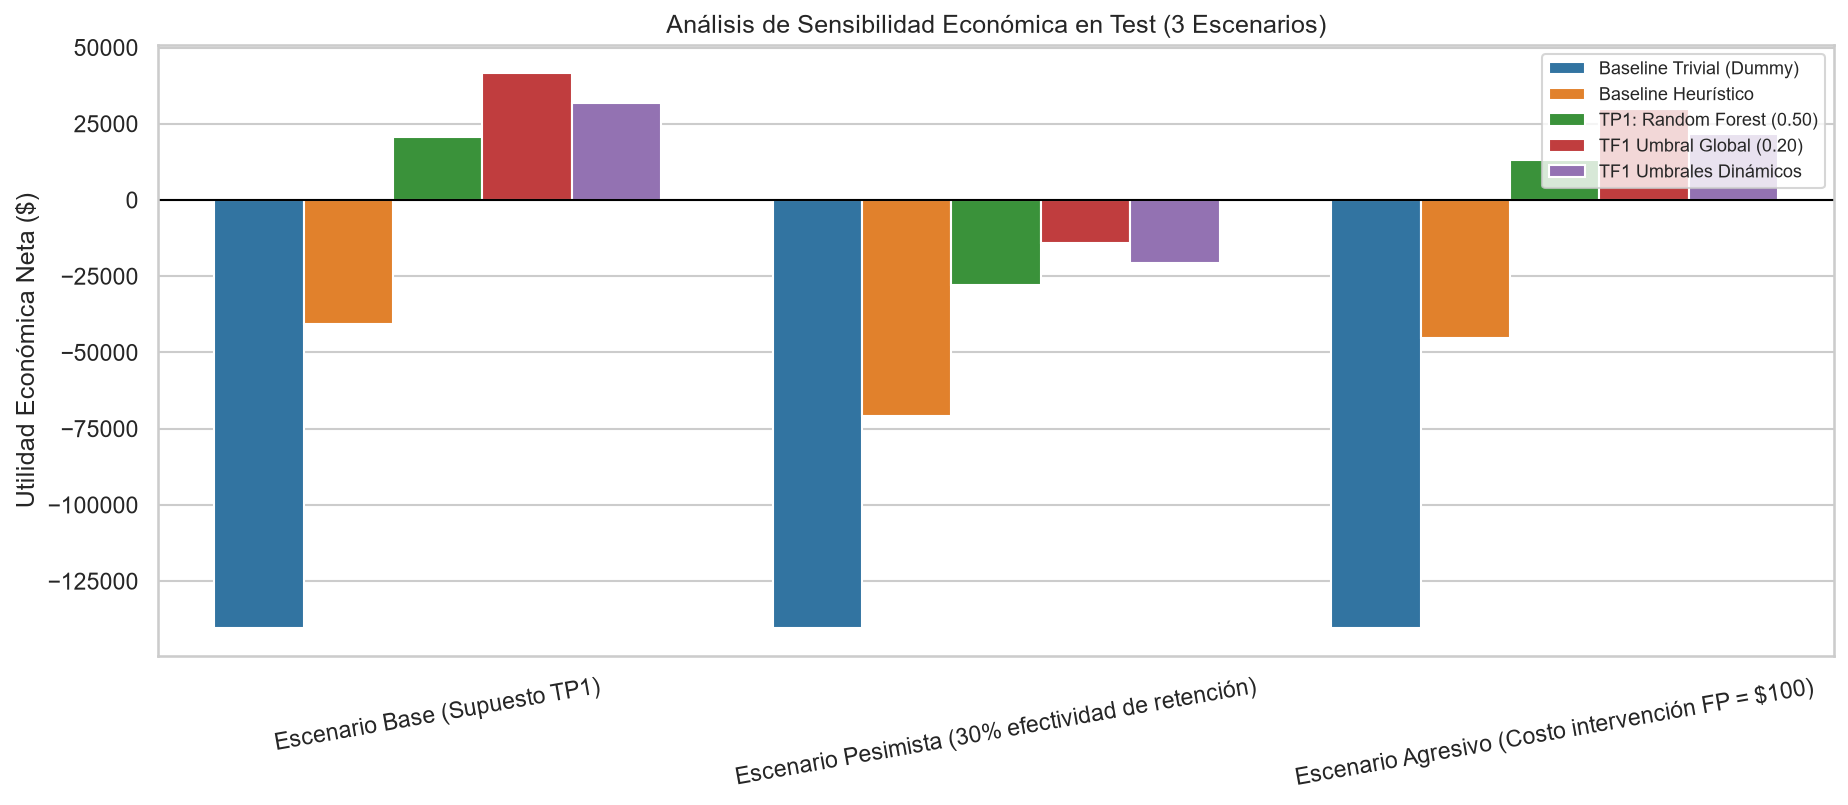

In [4]:
df_test = pd.read_csv(REPORTS_DIR / "evaluacion_final_test_tf1.csv")
cols_t = [
    "Modelo", "PR-AUC", "ROC-AUC", "Recall (Clase 1)",
    "Value-Weighted Recall", "Precision (Clase 1)", "F1-Score", "Valor Económico Neto ($)"
]
display(df_test[cols_t].round(4))

df_sens = pd.read_csv(REPORTS_DIR / "sensibilidad_economica_tf1.csv")
display(df_sens.pivot(index="Modelo", columns="Escenario", values="Valor Económico Neto ($)").round(0))

display(Image(filename=str(FIGURES_TF1_DIR / "comparacion_tp1_vs_tf1_test.png")))
display(Image(filename=str(FIGURES_TF1_DIR / "sensibilidad_economica.png")))

**Interpretación en Test Holdout (1,057 clientes):**
- **Superación completa del TP1:** El modelo TF1 (`Stacking` con $\tau^* = 0.20$) eleva `PR-AUC` de `0.6698` a `0.6719`, `ROC-AUC` de `0.8400` a `0.8443`, resuelve la brecha de `Recall` pasando de `70.46%` (incumplido en TP1) a **`81.14%`**, rescata el **`84.12%` de los ingresos mensuales en riesgo (`Value-Weighted Recall`)** y **duplica la utilidad neta simulada de `+$20,500` a `+$41,600`**.
- **Política de Umbrales Dinámicos por Cluster (`C0=0.30, C1=0.22, C2=0.21`):** Mantiene `Precision >= 50.9%`, `Recall = 76.5%`, `Value-Weighted Recall = 82.0%` y `+$31,900` de utilidad (+55.6% sobre TP1), constituyendo la opción más conservadora cuando el presupuesto de contacto es limitado.
- **Sensibilidad económica:** En los 3 escenarios (Base, Pesimista 30% de efectividad y Agresivo FP=`$100`), la solución TF1 supera consistentemente al TP1 y a ambos baselines.